Name: Rutuja Kamale

Roll NO.: 23102A0028

BE CMPN A


In [2]:

packages <- c(
  "data.table",
  "ggplot2",
  "lubridate",
  "arrow",
  "foreach",
  "doParallel",
  "microbenchmark",
  "purrr"
)

installed <- rownames(installed.packages())
missing <- setdiff(packages, installed)

if (length(missing) > 0) {
  install.packages(missing, repos = "https://cloud.r-project.org")
}

cat("All required R packages are ready!\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘assertthat’, ‘iterators’




All required R packages are ready!


In [3]:
library(data.table)
library(ggplot2)
library(lubridate)
library(arrow)
library(foreach)
library(doParallel)
library(microbenchmark)
library(purrr)

cat("R version:", R.version.string, "\n")
cat("Available CPU cores:", parallel::detectCores(), "\n")


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%



Attaching package: ‘lubridate’


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union



Attaching package: ‘arrow’


The following object is masked from ‘package:lubridate’:

    duration


The following object is masked from ‘package:utils’:

    timestamp


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘purrr’


The following objects are masked from ‘package:foreach’:

    accumulate, when


The following object is masked from ‘package:data.table’:

    transpose




R version: R version 4.6.1 (2026-06-24) 
Available CPU cores: 2 


In [4]:
trip_url <- paste0(
  "https://d37ci6vzurychx.cloudfront.net/",
  "trip-data/yellow_tripdata_2025-01.parquet"
)

zone_url <- paste0(
  "https://d37ci6vzurychx.cloudfront.net/",
  "misc/taxi_zone_lookup.csv"
)

download.file(
  trip_url,
  "yellow_tripdata_2025-01.parquet",
  mode = "wb"
)

download.file(
  zone_url,
  "taxi_zone_lookup.csv",
  mode = "wb"
)

cat("Dataset files downloaded successfully!\n")

Dataset files downloaded successfully!


In [5]:
taxi <- as.data.table(
  arrow::read_parquet("yellow_tripdata_2025-01.parquet")
)

zones <- fread("taxi_zone_lookup.csv")

cat("Number of rows:", nrow(taxi), "\n")
cat("Number of columns:", ncol(taxi), "\n")

cat("\nColumn names:\n")
print(names(taxi))

cat("\nDataset structure:\n")
str(taxi)

cat("\nSummary statistics:\n")
summary(taxi)

cat("\nTaxi zone lookup:\n")
head(zones)

Number of rows: 3475226 
Number of columns: 20 

Column names:
 [1] "VendorID"              "tpep_pickup_datetime"  "tpep_dropoff_datetime"
 [4] "passenger_count"       "trip_distance"         "RatecodeID"           
 [7] "store_and_fwd_flag"    "PULocationID"          "DOLocationID"         
[10] "payment_type"          "fare_amount"           "extra"                
[13] "mta_tax"               "tip_amount"            "tolls_amount"         
[16] "improvement_surcharge" "total_amount"          "congestion_surcharge" 
[19] "Airport_fee"           "cbd_congestion_fee"   

Dataset structure:
Classes ‘data.table’ and 'data.frame':	3475226 obs. of  20 variables:
 $ VendorID             : int  1 1 1 2 2 2 1 1 1 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2025-01-01 00:18:38" "2025-01-01 00:32:40" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2025-01-01 00:26:59" "2025-01-01 00:35:13" ...
 $ passenger_count      : int  1 1 1 3 3 2 0 0 0 1 ...
 $ trip_distance        : num  1.6 0.5 0

    VendorID     tpep_pickup_datetime          tpep_dropoff_datetime        
 Min.   :1.000   Min.   :2024-12-31 20:47:55   Min.   :2024-12-18 07:52:40  
 1st Qu.:2.000   1st Qu.:2025-01-10 07:59:01   1st Qu.:2025-01-10 08:15:29  
 Median :2.000   Median :2025-01-17 15:41:33   Median :2025-01-17 15:59:34  
 Mean   :1.785   Mean   :2025-01-17 11:02:55   Mean   :2025-01-17 11:17:57  
 3rd Qu.:2.000   3rd Qu.:2025-01-24 19:34:06   3rd Qu.:2025-01-24 19:48:31  
 Max.   :7.000   Max.   :2025-02-01 00:00:44   Max.   :2025-02-01 23:44:11  
                                                                            
 passenger_count  trip_distance         RatecodeID     store_and_fwd_flag 
 Min.   :0.000    Min.   :0.000e+00   Min.   : 1.000   Length   :3475226  
 1st Qu.:1.000    1st Qu.:9.800e-01   1st Qu.: 1.000   N.unique :      2  
 Median :1.000    Median :1.670e+00   Median : 1.000   N.blank  :      0  
 Mean   :1.298    Mean   :5.855e+00   Mean   : 2.483   Min.nchar:      1  
 3rd Qu.:


Taxi zone lookup:


LocationID,Borough,Zone,service_zone
<int>,<chr>,<chr>,<chr>
1,EWR,Newark Airport,EWR
2,Queens,Jamaica Bay,Boro Zone
3,Bronx,Allerton/Pelham Gardens,Boro Zone
4,Manhattan,Alphabet City,Yellow Zone
5,Staten Island,Arden Heights,Boro Zone
6,Staten Island,Arrochar/Fort Wadsworth,Boro Zone


In [6]:
cat("Missing values in each column:\n")
print(colSums(is.na(taxi)))

cat("\nNumber of duplicate rows:\n")
print(sum(duplicated(taxi)))

cat("\nInvalid trip distances:\n")
print(sum(taxi$trip_distance <= 0, na.rm = TRUE))

cat("\nInvalid fare amounts:\n")
print(sum(taxi$fare_amount < 0, na.rm = TRUE))

Missing values in each column:
             VendorID  tpep_pickup_datetime tpep_dropoff_datetime 
                    0                     0                     0 
      passenger_count         trip_distance            RatecodeID 
               540149                     0                540149 
   store_and_fwd_flag          PULocationID          DOLocationID 
               540149                     0                     0 
         payment_type           fare_amount                 extra 
                    0                     0                     0 
              mta_tax            tip_amount          tolls_amount 
                    0                     0                     0 
improvement_surcharge          total_amount  congestion_surcharge 
                    0                     0                540149 
          Airport_fee    cbd_congestion_fee 
               540149                     0 

Number of duplicate rows:
[1] 0

Invalid trip distances:
[1] 90893

Invali

In [7]:
taxi <- unique(taxi)

taxi <- taxi[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  !is.na(trip_distance) &
  !is.na(fare_amount) &
  !is.na(total_amount)
]

taxi <- taxi[
  trip_distance > 0 &
  fare_amount >= 0 &
  total_amount >= 0 &
  tpep_dropoff_datetime >= tpep_pickup_datetime
]

taxi[, pickup_hour := hour(tpep_pickup_datetime)]
taxi[, pickup_day := day(tpep_pickup_datetime)]
taxi[, pickup_weekday := wday(
  tpep_pickup_datetime, label = TRUE, week_start = 1
)]
taxi[, pickup_month := month(
  tpep_pickup_datetime, label = TRUE, abbr = TRUE
)]

cat("Rows after cleaning:", nrow(taxi), "\n")
cat("Columns after feature engineering:", ncol(taxi), "\n")

head(taxi)

Rows after cleaning: 3254338 
Columns after feature engineering: 24 


VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,⋯,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,pickup_hour,pickup_day,pickup_weekday,pickup_month
<int>,<dttm>,<dttm>,<int>,<dbl>,<int>,<chr>,<int>,<int>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<ord>,<ord>
1,2025-01-01 00:18:38,2025-01-01 00:26:59,1,1.60,1,N,229,237,1,⋯,0,1,18.00,2.5,0,0,0,1,Wed,Jan
1,2025-01-01 00:32:40,2025-01-01 00:35:13,1,0.50,1,N,236,237,1,⋯,0,1,12.12,2.5,0,0,0,1,Wed,Jan
1,2025-01-01 00:44:04,2025-01-01 00:46:01,1,0.60,1,N,141,141,1,⋯,0,1,12.10,2.5,0,0,0,1,Wed,Jan
2,2025-01-01 00:14:27,2025-01-01 00:20:01,3,0.52,1,N,244,244,2,⋯,0,1,9.70,0.0,0,0,0,1,Wed,Jan
2,2025-01-01 00:21:34,2025-01-01 00:25:06,3,0.66,1,N,244,116,2,⋯,0,1,8.30,0.0,0,0,0,1,Wed,Jan
2,2025-01-01 00:48:24,2025-01-01 01:08:26,2,2.63,1,N,239,68,2,⋯,0,1,24.10,2.5,0,0,0,1,Wed,Jan


In [8]:
# Prepare pickup-zone information
pickup_zones <- zones[, .(
  PULocationID = LocationID,
  pickup_zone = Zone,
  pickup_borough = Borough
)]

# Prepare drop-off-zone information
dropoff_zones <- zones[, .(
  DOLocationID = LocationID,
  dropoff_zone = Zone,
  dropoff_borough = Borough
)]

# Join pickup information
taxi <- merge(
  taxi,
  pickup_zones,
  by = "PULocationID",
  all.x = TRUE,
  sort = FALSE
)

# Join drop-off information
taxi <- merge(
  taxi,
  dropoff_zones,
  by = "DOLocationID",
  all.x = TRUE,
  sort = FALSE
)

cat("Joined dataset dimensions:\n")
print(dim(taxi))

cat("\nSample joined records:\n")
print(head(taxi[, .(
  pickup_zone, pickup_borough,
  dropoff_zone, dropoff_borough,
  trip_distance, fare_amount, total_amount
)]))

Joined dataset dimensions:
[1] 3254338      28

Sample joined records:
                     pickup_zone pickup_borough             dropoff_zone
                          <char>         <char>                   <char>
1: Sutton Place/Turtle Bay North      Manhattan    Upper East Side South
2:         Upper East Side North      Manhattan    Upper East Side South
3:               Lenox Hill West      Manhattan          Lenox Hill West
4:      Washington Heights South      Manhattan Washington Heights South
5:      Washington Heights South      Manhattan         Hamilton Heights
6:         Upper West Side South      Manhattan             East Chelsea
   dropoff_borough trip_distance fare_amount total_amount
            <char>         <num>       <num>        <num>
1:       Manhattan          1.60        10.0        18.00
2:       Manhattan          0.50         5.1        12.12
3:       Manhattan          0.60         5.1        12.10
4:       Manhattan          0.52         7.2         9.

In [9]:
# Number of trips by hour
hourly_trips <- taxi[, .(trips = .N), by = pickup_hour][
  order(pickup_hour)
]

# Number of trips by weekday
weekday_trips <- taxi[, .(trips = .N), by = pickup_weekday][
  order(pickup_weekday)
]

# Number of trips by month
monthly_trips <- taxi[, .(trips = .N), by = pickup_month]

cat("Trips by hour:\n")
print(hourly_trips)

cat("\nTrips by weekday:\n")
print(weekday_trips)

cat("\nTrips by month:\n")
print(monthly_trips)

Trips by hour:
    pickup_hour  trips
          <int>  <int>
 1:           0  86562
 2:           1  59525
 3:           2  40228
 4:           3  25574
 5:           4  17936
 6:           5  20529
 7:           6  46622
 8:           7  96808
 9:           8 133871
10:           9 137280
11:          10 143062
12:          11 154420
13:          12 168520
14:          13 178559
15:          14 193971
16:          15 204555
17:          16 203152
18:          17 229403
19:          18 236628
20:          19 200682
21:          20 184642
22:          21 194224
23:          22 170529
24:          23 127056
    pickup_hour  trips
          <int>  <int>

Trips by weekday:
   pickup_weekday  trips
            <ord>  <int>
1:            Mon 343652
2:            Tue 426357
3:            Wed 537318
4:            Thu 571955
5:            Fri 544398
6:            Sat 451517
7:            Sun 379141

Trips by month:
   pickup_month   trips
          <ord>   <int>
1:          Jan 3254316
2:      

In [10]:
fare_summary <- taxi[, .(
  total_trips = .N,
  average_fare = mean(fare_amount, na.rm = TRUE),
  average_distance = mean(trip_distance, na.rm = TRUE),
  total_revenue = sum(total_amount, na.rm = TRUE)
)]

cat("Overall fare and revenue summary:\n")
print(fare_summary)

cat("\nFare and revenue by hour:\n")
hourly_revenue <- taxi[, .(
  trips = .N,
  average_fare = mean(fare_amount, na.rm = TRUE),
  revenue = sum(total_amount, na.rm = TRUE)
), by = pickup_hour][order(pickup_hour)]

print(hourly_revenue)

Overall fare and revenue summary:
   total_trips average_fare average_distance total_revenue
         <int>        <num>            <num>         <num>
1:     3254338     18.21862         5.513524      88130940

Fare and revenue by hour:
    pickup_hour  trips average_fare   revenue
          <int>  <int>        <num>     <num>
 1:           0  86562     18.73404 2361324.7
 2:           1  59525     17.15787 1497069.9
 3:           2  40228     16.34242  968589.1
 4:           3  25574     17.14327  639137.4
 5:           4  17936     22.13894  551134.8
 6:           5  20529     25.46504  713575.4
 7:           6  46622     21.28226 1355834.0
 8:           7  96808     19.08967 2585187.3
 9:           8 133871     17.72874 3380137.2
10:           9 137280     17.34253 3481508.8
11:          10 143062     17.46366 3682851.3
12:          11 154420     17.28418 3931694.7
13:          12 168520     22.69076 5214953.8
14:          13 178559     18.06413 4726671.7
15:          14 193971    

In [11]:
popular_routes <- taxi[, .(
  trips = .N,
  revenue = sum(total_amount, na.rm = TRUE)
), by = .(pickup_zone, dropoff_zone)][
  order(-trips)
][1:min(10, .N)]

revenue_routes <- taxi[, .(
  trips = .N,
  revenue = sum(total_amount, na.rm = TRUE)
), by = .(pickup_zone, dropoff_zone)][
  order(-revenue)
][1:min(10, .N)]

cat("Top 10 most frequently travelled routes:\n")
print(popular_routes)

cat("\nTop 10 routes by total revenue:\n")
print(revenue_routes)

Top 10 most frequently travelled routes:
              pickup_zone          dropoff_zone trips  revenue
                   <char>                <char> <int>    <num>
 1: Upper East Side South Upper East Side North 24394 380422.4
 2: Upper East Side North Upper East Side South 21354 336979.5
 3: Upper East Side North Upper East Side North 17143 226501.9
 4: Upper East Side South Upper East Side South 16268 224676.8
 5:        Midtown Center Upper East Side South 11163 196946.1
 6: Upper East Side South        Midtown Center  9900 175155.0
 7:        Midtown Center Upper East Side North  9587 213411.0
 8: Upper West Side South Upper West Side North  9329 128455.4
 9:   Lincoln Square East Upper West Side South  8944 133874.1
10: Upper West Side South   Lincoln Square East  8575 123558.6

Top 10 routes by total revenue:
                  pickup_zone              dropoff_zone trips  revenue
                       <char>                    <char> <int>    <num>
 1:         LaGuardia Airpor

In [12]:
cat("Payment type distribution:\n")

payment_summary <- taxi[, .(
  trips = .N,
  total_revenue = sum(total_amount, na.rm = TRUE)
), by = payment_type][order(-trips)]

print(payment_summary)

cat("\nPayment methods by pickup borough:\n")

borough_payment <- taxi[, .(
  trips = .N
), by = .(pickup_borough, payment_type)][order(-trips)]

print(borough_payment)

cat("\nCorrelation between trip distance and fare:\n")

print(cor(
  taxi$trip_distance,
  taxi$fare_amount,
  use = "complete.obs"
))

Payment type distribution:
   payment_type   trips total_revenue
          <int>   <int>         <num>
1:            1 2424727    67722597.6
2:            0  413304     9570422.3
3:            2  368311     8697506.0
4:            4   35731     1846464.1
5:            3   12265      293949.9

Payment methods by pickup borough:
    pickup_borough payment_type   trips
            <char>        <int>   <int>
 1:      Manhattan            1 2194660
 2:      Manhattan            0  351339
 3:      Manhattan            2  323786
 4:         Queens            1  196169
 5:         Queens            2   40845
 6:       Brooklyn            0   31391
 7:      Manhattan            4   28335
 8:         Queens            0   23365
 9:       Brooklyn            1   21834
10:      Manhattan            3   10070
11:         Queens            4    7018
12:          Bronx            0    6862
13:        Unknown            1    6220
14:          Bronx            1    5387
15:         Queens            3

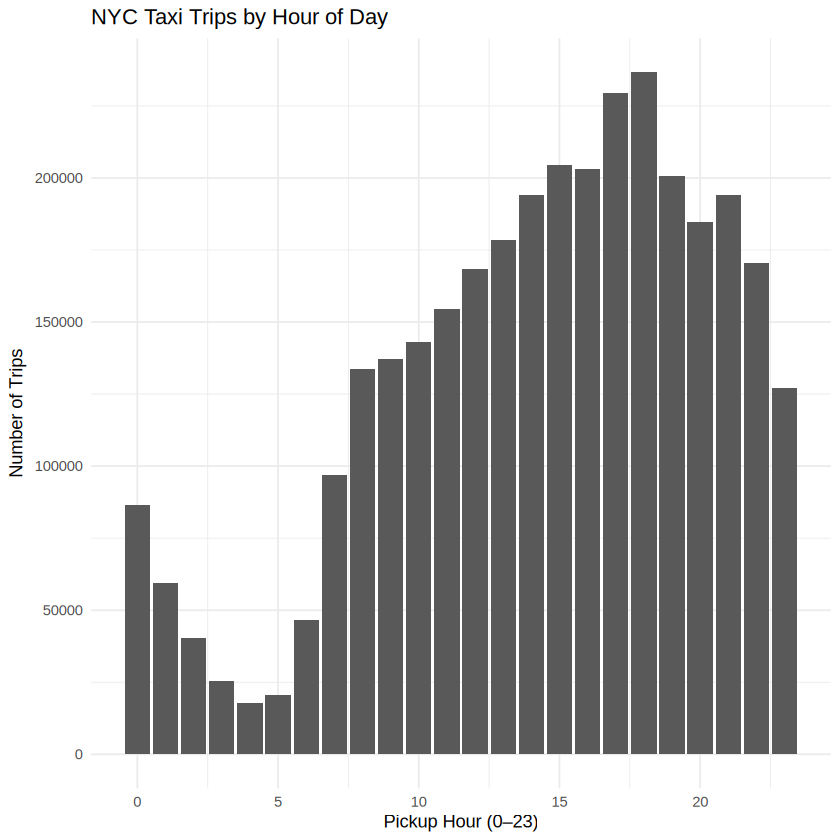

In [13]:
ggplot(hourly_trips, aes(x = pickup_hour, y = trips)) +
  geom_col() +
  labs(
    title = "NYC Taxi Trips by Hour of Day",
    x = "Pickup Hour (0–23)",
    y = "Number of Trips"
  ) +
  theme_minimal()

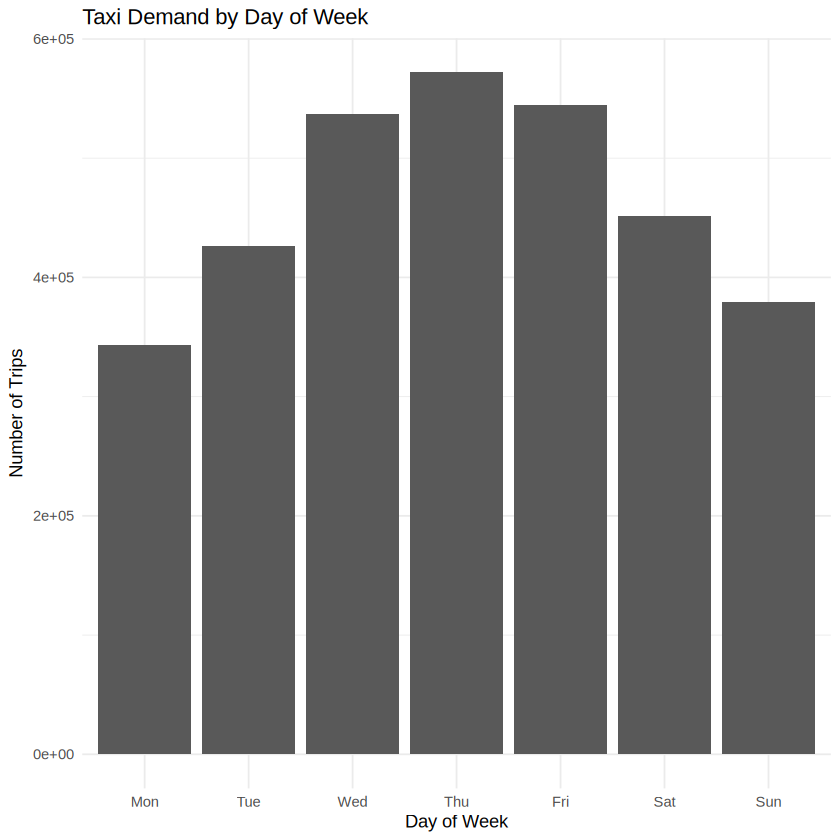

In [14]:
ggplot(weekday_trips, aes(x = pickup_weekday, y = trips)) +
  geom_col() +
  labs(
    title = "Taxi Demand by Day of Week",
    x = "Day of Week",
    y = "Number of Trips"
  ) +
  theme_minimal()

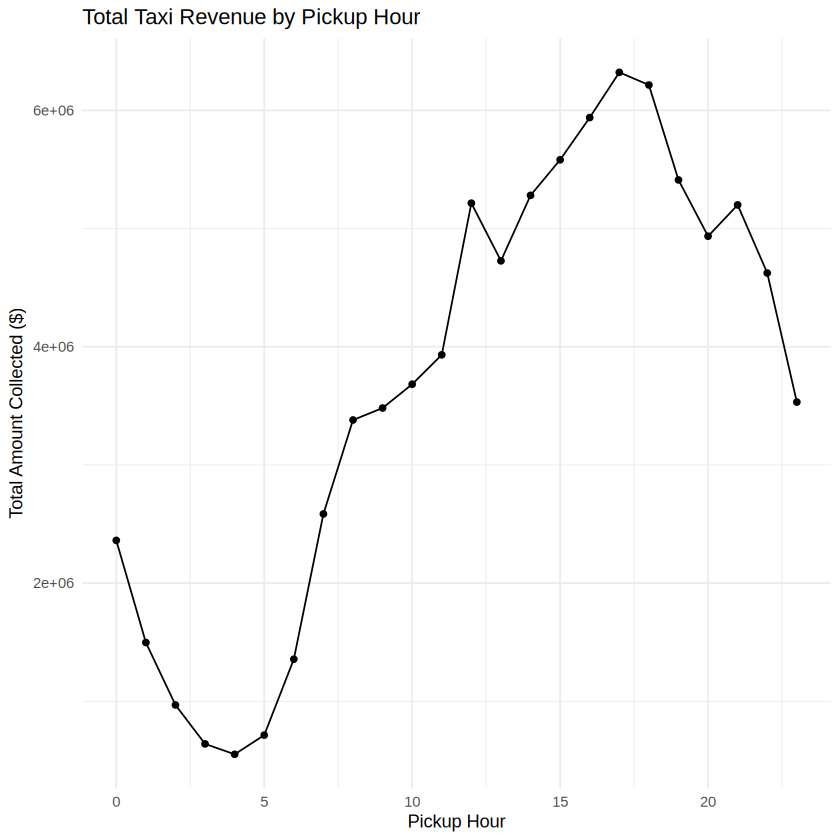

In [15]:
ggplot(hourly_revenue, aes(x = pickup_hour, y = revenue)) +
  geom_line() +
  geom_point() +
  labs(
    title = "Total Taxi Revenue by Pickup Hour",
    x = "Pickup Hour",
    y = "Total Amount Collected ($)"
  ) +
  theme_minimal()

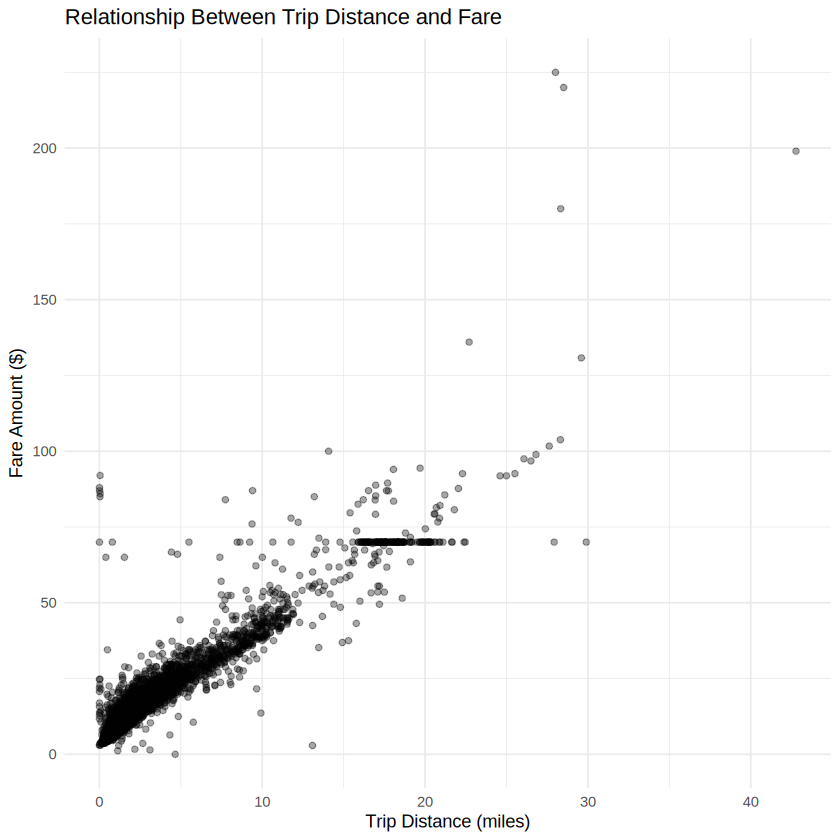

In [16]:
set.seed(42)

plot_data <- taxi[
  sample(.N, min(.N, 5000)),
  .(trip_distance, fare_amount)
]

ggplot(plot_data, aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.35) +
  labs(
    title = "Relationship Between Trip Distance and Fare",
    x = "Trip Distance (miles)",
    y = "Fare Amount ($)"
  ) +
  theme_minimal()

In [17]:
set.seed(123)

benchmark_data <- taxi[
  sample(.N, min(.N, 100000)),
  .(trip_distance, fare_amount, tip_amount, total_amount)
]

benchmark_df <- as.data.frame(benchmark_data)

cat("Rows used for benchmarking:", nrow(benchmark_df), "\n")

Rows used for benchmarking: 100000 


In [18]:
# 1. Base R using lapply()
base_lapply <- function() {
  lapply(benchmark_df, mean, na.rm = TRUE)
}

# 2. Vectorized operation
vectorized_mean <- function() {
  colMeans(as.matrix(benchmark_df), na.rm = TRUE)
}

# 3. Functional programming using purrr::map()
purrr_map <- function() {
  purrr::map(benchmark_df, mean, na.rm = TRUE)
}

# 4. data.table implementation
datatable_mean <- function() {
  benchmark_data[, lapply(.SD, mean, na.rm = TRUE)]
}

# Verify results
print(base_lapply())
print(vectorized_mean())
print(purrr_map())
print(datatable_mean())

$trip_distance
[1] 5.646943

$fare_amount
[1] 17.9348

$tip_amount
[1] 3.128242

$total_amount
[1] 26.7971

trip_distance   fare_amount    tip_amount  total_amount 
     5.646943     17.934804      3.128242     26.797096 
$trip_distance
[1] 5.646943

$fare_amount
[1] 17.9348

$tip_amount
[1] 3.128242

$total_amount
[1] 26.7971

   trip_distance fare_amount tip_amount total_amount
           <num>       <num>      <num>        <num>
1:      5.646943     17.9348   3.128242      26.7971


In [19]:
benchmark_results <- microbenchmark(
  Base_R_lapply = base_lapply(),
  Vectorized = vectorized_mean(),
  Purrr_map = purrr_map(),
  DataTable = datatable_mean(),
  times = 10L,
  unit = "ms"
)

print(benchmark_results)

benchmark_summary <- summary(benchmark_results)[
  , c("expr", "min", "median", "mean", "max")
]

print(benchmark_summary)

Unit: milliseconds
          expr      min       lq     mean   median       uq       max neval
 Base_R_lapply 5.367733 5.833747 7.088867 6.301124 9.060733 10.242848    10
    Vectorized 2.223925 2.266085 2.709019 2.327462 2.367126  6.179879    10
     Purrr_map 5.260530 5.642011 6.678294 5.871487 8.259482  9.628853    10
     DataTable 7.382225 7.524223 8.971368 7.896651 8.412223 13.785045    10
           expr      min   median     mean       max
1 Base_R_lapply 5.367733 6.301124 7.088867 10.242848
2    Vectorized 2.223925 2.327462 2.709019  6.179879
3     Purrr_map 5.260530 5.871487 6.678294  9.628853
4     DataTable 7.382225 7.896651 8.971368 13.785045


In [20]:

# Divide records into at most four chunks
number_of_chunks <- min(
  4L,
  max(1L, nrow(taxi))
)

chunk_id <- cut(
  seq_len(nrow(taxi)),
  breaks = number_of_chunks,
  labels = FALSE
)

chunks <- split(taxi[, .(pickup_hour)], chunk_id)

sequential_time <- system.time({
  sequential_results <- lapply(chunks, function(chunk) {
    chunk[, .(trips = .N), by = pickup_hour]
  })

  sequential_summary <- rbindlist(sequential_results)[
    , .(trips = sum(trips)),
    by = pickup_hour
  ][order(pickup_hour)]
})

cat("Sequential execution time:\n")
print(sequential_time)

print(sequential_summary)

Sequential execution time:
   user  system elapsed 
  0.084   0.000   0.084 
    pickup_hour  trips
          <int>  <int>
 1:           0  86562
 2:           1  59525
 3:           2  40228
 4:           3  25574
 5:           4  17936
 6:           5  20529
 7:           6  46622
 8:           7  96808
 9:           8 133871
10:           9 137280
11:          10 143062
12:          11 154420
13:          12 168520
14:          13 178559
15:          14 193971
16:          15 204555
17:          16 203152
18:          17 229403
19:          18 236628
20:          19 200682
21:          20 184642
22:          21 194224
23:          22 170529
24:          23 127056
    pickup_hour  trips
          <int>  <int>


In [21]:
library(parallel)

cores <- min(
  2L,
  max(1L, parallel::detectCores() - 1L)
)

cl <- parallel::makeCluster(cores)
doParallel::registerDoParallel(cl)

parallel_time <- system.time({
  parallel_results <- foreach(
    i = seq_along(chunks),
    .combine = rbind,
    .packages = "data.table"
  ) %dopar% {
    chunks[[i]][, .(trips = .N), by = pickup_hour]
  }

  parallel_summary <- as.data.table(parallel_results)[
    , .(trips = sum(trips)),
    by = pickup_hour
  ][order(pickup_hour)]
})

parallel::stopCluster(cl)
foreach::registerDoSEQ()

cat("Parallel execution time:\n")
print(parallel_time)

cat("\nParallel results:\n")
print(parallel_summary)

Parallel execution time:
   user  system elapsed 
  0.054   0.009   0.292 

Parallel results:
    pickup_hour  trips
          <int>  <int>
 1:           0  86562
 2:           1  59525
 3:           2  40228
 4:           3  25574
 5:           4  17936
 6:           5  20529
 7:           6  46622
 8:           7  96808
 9:           8 133871
10:           9 137280
11:          10 143062
12:          11 154420
13:          12 168520
14:          13 178559
15:          14 193971
16:          15 204555
17:          16 203152
18:          17 229403
19:          18 236628
20:          19 200682
21:          20 184642
22:          21 194224
23:          22 170529
24:          23 127056
    pickup_hour  trips
          <int>  <int>


In [23]:
seq_seconds <- unname(sequential_time["elapsed"])
par_seconds <- unname(parallel_time["elapsed"])

speedup <- if (par_seconds > 0) {
  seq_seconds / par_seconds
} else {
  NA_real_
}

cat("Sequential time:", seq_seconds, "seconds\n")
cat("Parallel time:", par_seconds, "seconds\n")
cat("Speedup:", round(speedup, 3), "x\n")

cat("\nAre sequential and parallel results identical?\n")

comparison <- merge(
  sequential_summary,
  parallel_summary,
  by = "pickup_hour",
  all = TRUE,
  suffixes = c("_seq", "_par")
)

print(comparison)

stopifnot(
  isTRUE(all.equal(
    sequential_summary,
    parallel_summary,
    check.attributes = FALSE
  ))
)

cat("Verification successful: both methods give the same results.\n")

Sequential time: 0.084 seconds
Parallel time: 0.292 seconds
Speedup: 0.288 x

Are sequential and parallel results identical?
Key: <pickup_hour>
    pickup_hour trips_seq trips_par
          <int>     <int>     <int>
 1:           0     86562     86562
 2:           1     59525     59525
 3:           2     40228     40228
 4:           3     25574     25574
 5:           4     17936     17936
 6:           5     20529     20529
 7:           6     46622     46622
 8:           7     96808     96808
 9:           8    133871    133871
10:           9    137280    137280
11:          10    143062    143062
12:          11    154420    154420
13:          12    168520    168520
14:          13    178559    178559
15:          14    193971    193971
16:          15    204555    204555
17:          16    203152    203152
18:          17    229403    229403
19:          18    236628    236628
20:          19    200682    200682
21:          20    184642    184642
22:          21    194224   

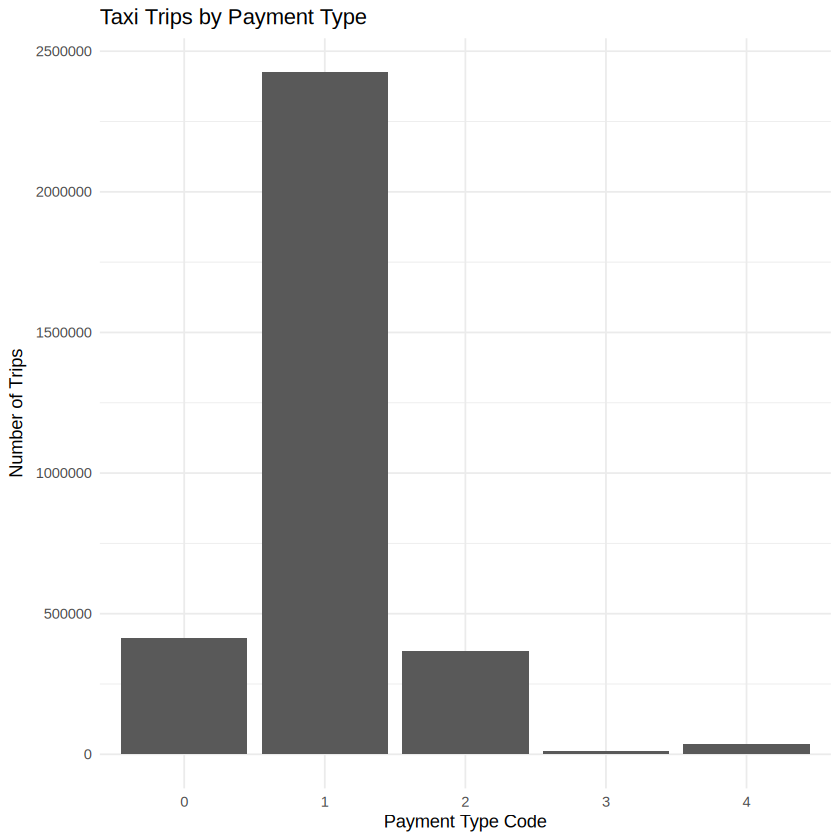

In [24]:
payment_plot <- taxi[
  !is.na(payment_type),
  .(trips = .N),
  by = payment_type
]

ggplot(payment_plot, aes(
  x = factor(payment_type),
  y = trips
)) +
  geom_col() +
  labs(
    title = "Taxi Trips by Payment Type",
    x = "Payment Type Code",
    y = "Number of Trips"
  ) +
  theme_minimal()

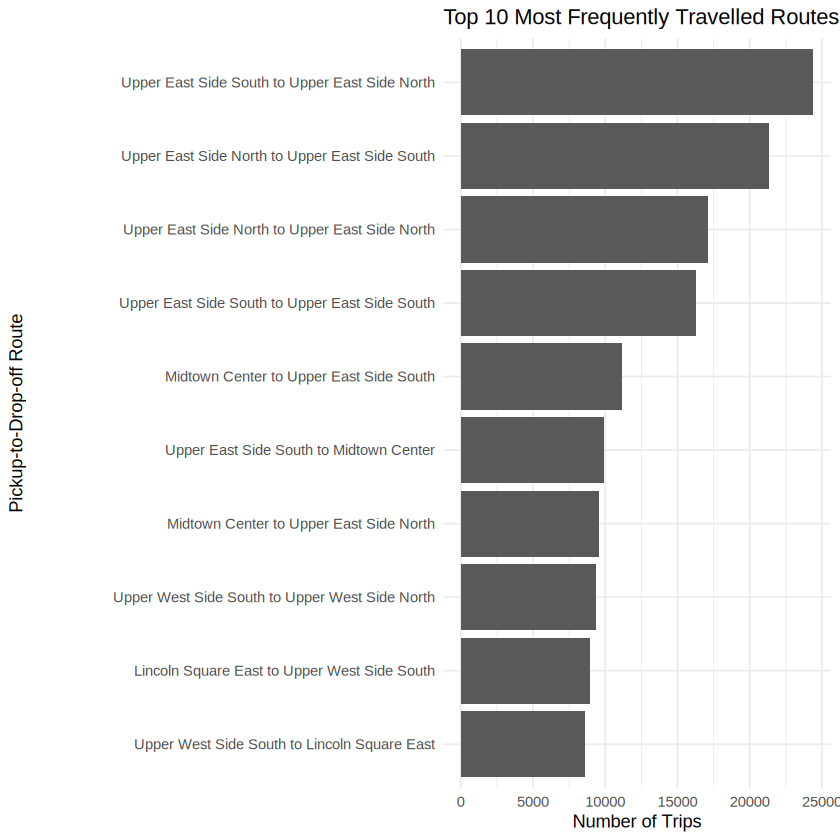

In [25]:
popular_routes[, route := paste(
  pickup_zone, "to", dropoff_zone
)]

ggplot(
  popular_routes,
  aes(x = reorder(route, trips), y = trips)
) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Top 10 Most Frequently Travelled Routes",
    x = "Pickup-to-Drop-off Route",
    y = "Number of Trips"
  ) +
  theme_minimal()

In [26]:
cat("FINAL EXPERIMENT SUMMARY\n")
cat("========================\n")

cat("\n1. Dataset and preprocessing\n")
cat("Cleaned records:", nrow(taxi), "\n")
cat("Variables available:", ncol(taxi), "\n")

cat("\n2. Transportation analytics\n")
cat("Total revenue collected: $",
    round(sum(taxi$total_amount, na.rm = TRUE), 2), "\n")

cat("Average fare: $",
    round(mean(taxi$fare_amount, na.rm = TRUE), 2), "\n")

cat("Average trip distance:",
    round(mean(taxi$trip_distance, na.rm = TRUE), 2),
    "miles\n")

cat("\n3. Functional programming benchmark\n")
print(benchmark_summary)

fastest <- benchmark_summary[
  which.min(benchmark_summary$median),
  "expr"
]

cat("Fastest implementation in this benchmark:",
    as.character(fastest), "\n")

cat("\n4. Sequential and parallel processing\n")
cat("Sequential time:", seq_seconds, "seconds\n")
cat("Parallel time:", par_seconds, "seconds\n")
cat("Speedup:", round(speedup, 3), "x\n")

cat("\n5. Conclusion\n")
cat(
  "data.table provides convenient grouping and aggregation for ",
  "large datasets. Vectorized operations can be efficient for ",
  "simple numerical calculations, while functional programming ",
  "supports reusable and readable operations. Parallel processing ",
  "may improve performance for sufficiently large independent tasks, ",
  "but overhead can make it slower for smaller workloads.\n",
  sep = ""
)

FINAL EXPERIMENT SUMMARY

1. Dataset and preprocessing
Cleaned records: 3254338 
Variables available: 28 

2. Transportation analytics
Total revenue collected: $ 88130940 
Average fare: $ 18.22 
Average trip distance: 5.51 miles

3. Functional programming benchmark
           expr      min   median     mean       max
1 Base_R_lapply 5.367733 6.301124 7.088867 10.242848
2    Vectorized 2.223925 2.327462 2.709019  6.179879
3     Purrr_map 5.260530 5.871487 6.678294  9.628853
4     DataTable 7.382225 7.896651 8.971368 13.785045
Fastest implementation in this benchmark: Vectorized 

4. Sequential and parallel processing
Sequential time: 0.084 seconds
Parallel time: 0.292 seconds
Speedup: 0.288 x

5. Conclusion
data.table provides convenient grouping and aggregation for large datasets. Vectorized operations can be efficient for simple numerical calculations, while functional programming supports reusable and readable operations. Parallel processing may improve performance for sufficiently l